# Import libraries

In [50]:
# Import libraries
import numpy as np
import pandas as pd
import scipy
from pathlib import Path
from io import StringIO
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.optimize import curve_fit
from scipy.stats import norm
from iminuit import cost as cost, Minuit
from statsmodels.stats.moment_helpers import corr2cov

# Set a random seed for reproducibility
RANDOM_SEED = 42

Load in the data and plot it to get an idea of the shape.

# Load in and plot data

In [140]:
# Load in data
data = np.loadtxt("project-datafile.txt")

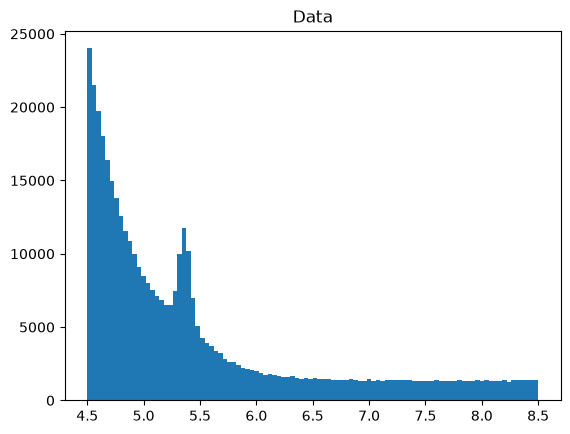

In [141]:
# Plot the data to get an idea of the shape and normalise the histogram to have a total area of 1
plt.hist(data, bins = 100)#, density = True)
plt.title("Data")
plt.show()

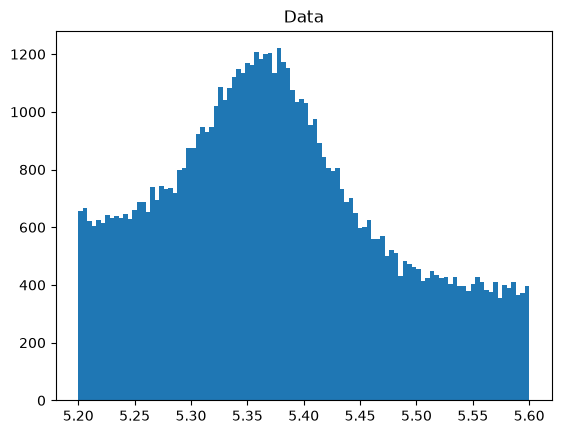

In [188]:
# Zoom in on the Gaussian
plt.hist(data, bins = 100, range = (5.2, 5.6))#, density = True)
plt.title("Data")
plt.show()

By inspection, the width of the gaussian looks approximately 0.25 centered on 5.375.

In [142]:
data_mean = np.mean(data)
data_min = np.min(data)
data_max = np.max(data)

print(f"Mean: {data_mean}")
print(f"Min: {data_min}")
print(f"Max: {data_max}")

Mean: 5.467110294198769
Min: 4.500000666103391
Max: 8.499985012426993


# Define Functions

This looks like an exponential with a small gaussian / noise. Let's define an exponential and gaussian function to fit the data to.

In [ ]:
# Exponential function
def exp_func(x, slope_exp):

    # Calculate CDF at upper and lower limit of the data
    cdf_lower = scipy.stats.expon.cdf(data_min, scale = slope_exp)
    cdf_upper = scipy.stats.expon.cdf(data_max, scale = slope_exp)

    # Probability between limits is the difference
    probs_between_limits = cdf_upper - cdf_lower

    # Normalise the pdf using the cdf 
    return scipy.stats.expon.pdf(x, scale = slope_exp) / probs_between_limits

In [305]:
# Gaussian function
def gauss_func(x, mean_gauss, width_gauss):

    # Calculate CDF at upper and lower limit of the data
    cdf_lower = scipy.stats.norm.cdf(data_min, loc = mean_gauss, scale = width_gauss)
    cdf_upper = scipy.stats.norm.cdf(data_max, loc = mean_gauss, scale = width_gauss)

    # Probability between limits is the difference
    probs_between_limits = cdf_upper - cdf_lower

    # Normalise the pdf using the cdf 
    return scipy.stats.norm.pdf(x, loc = mean_gauss, scale = width_gauss) / probs_between_limits

In [306]:
# Flat (uniform) PDF normalised over the data
def const_func(x):

    return np.full_like(x, 1 / (data_max - data_min), dtype = float)

In [307]:
# Exponential Gaussian function
def exp_gauss_func(x, frac_sig, frac_exp, slope_exp, mean_gauss, width_gauss):

    exp = exp_func(x, slope_exp)
    gauss = gauss_func(x, mean_gauss, width_gauss)
    constant = const_func(x)

    # Calculate fractions for the background
    frac_back = 1 - frac_sig
    frac_exp_share = frac_back * frac_exp
    frac_const_share = frac_back - frac_exp_share

    return frac_exp_share * exp + frac_sig * gauss + frac_const_share * constant

# Fit an exponential function

First, let's just fit an exponential function to get a rough idea of the slope of the exponential function.

In [308]:
# Define an unbinned NLL
cost_exp = cost.UnbinnedNLL(data, exp_func)

# First estimate of exponential decay parameter
slope_exp = np.mean(data)

# Run the fit
m_exp = Minuit(cost_exp, slope_exp)
m_exp.migrad()
m_exp.hesse()

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 7.778e+05                  │              Nfcn = 50               │
│ EDM = 8.61e-05 (Goal: 0.0002)    │            time = 1.6 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name      │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ slope_exp │  1.0617   │  0.0020   │            │            │         │         │       │
└───┴───────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌───────────┬───────────┐
│           │ slope_exp │
├───────────┼───────────┤
│ slope_exp │  4.18e-06 │
└───────────┴───────────┘

In [309]:
# Obtain the results
m_exp_value = m_exp.values[0]

# Print out results
print(m_exp)
print(m_exp_value)

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 7.778e+05                  │              Nfcn = 50               │
│ EDM = 8.61e-05 (Goal: 0.0002)    │            time = 1.6 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬─

Plot the graph with the exponential fit.

In [310]:
# Create an x-array
x_min_exp = min(data)
x_max_exp = max(data)
x_array = np.linspace(x_min_exp, x_max_exp, 100)

# Obtain data using the best fit parameter
best_fit_exp = exp_func(x_array, m_exp_value)

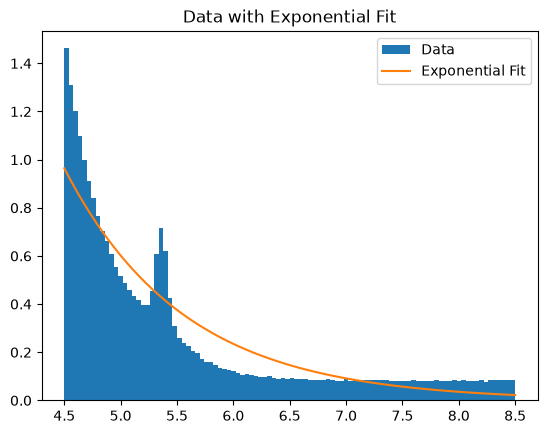

In [311]:
# Plot the data and normalise the histogram to have a total area of 1
plt.hist(data, bins = 100, label = "Data", density = True)
plt.plot(x_array, best_fit_exp, label = "Exponential Fit")
plt.title("Data with Exponential Fit")
plt.legend()
plt.show()

# Fit all of the data

Run a fit of the data using first estimates taken by eye.

In [312]:
# Define an unbinned NLL
cost_exp_gauss = cost.UnbinnedNLL(data, exp_gauss_func)

# First estimate of exponential gaussian parameters
# [slope_exp, mean_gauss]

frac_sig = 0.3
frac_exp = 0.3
slope_exp = m_exp_value
mean_gauss = 5.375
width_gauss = 0.25

# Run the fit
exp_gauss_vals = Minuit(cost_exp_gauss, frac_sig, frac_exp, slope_exp, mean_gauss, width_gauss)
#exp_gauss_vals.fixed["width_gauss"] = True # Fix the value of the width
exp_gauss_vals.limits["frac_sig"] = (0, 1)
exp_gauss_vals.limits["frac_exp"] = (0, 1)
exp_gauss_vals.limits["mean_gauss"] = (5.25, 5.50)
exp_gauss_vals.migrad()
exp_gauss_vals.hesse()

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 7.157e+05                  │              Nfcn = 659              │
│ EDM = 9.36e-07 (Goal: 0.0002)    │           time = 28.3 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name        │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼─────────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ frac_sig    │  63.1e-3  │  0.7e-3   │            │            │    0    │    1    │       │
│ 1 │ frac_exp    │  0.6613   │  0.0013   │            │            │    0    │    1    │       │
│ 2 │ slope_exp   │  0.4442   │  0.0017   │            │            │         │         │       │
│ 3 │ mean_gauss  │  5.3663   │  0.0007   │            │            │  5.25   │   5.5   │       │
│ 4 │ width_gauss │  58.9e-3  │  0.8e-3   │            │            │         │         │       │
└───┴─────────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌─────────────┬─────────────────────────────────────────────────────────────┐
│             │    frac_sig    frac_exp   slope_exp  mean_gauss width_gauss │
├─────────────┼─────────────────────────────────────────────────────────────┤
│    frac_sig │    5.04e-07     -0.3e-6     -0.5e-6          -0      0.3e-6 │
│    frac_exp │     -0.3e-6     1.8e-06      1.4e-6           0     -0.2e-6 │
│   slope_exp │     -0.5e-6      1.4e-6    2.89e-06           0     -0.4e-6 │
│  mean_gauss │          -0           0           0    4.42e-07          -0 │
│ width_gauss │      0.3e-6     -0.2e-6     -0.4e-6          -0     5.7e-07 │
└─────────────┴─────────────────────────────────────────────────────────────┘

In [320]:
# Obtain the results
frac_sig_value = exp_gauss_vals.values[0]
frac_exp_value = exp_gauss_vals.values[1]
slope_exp_value = exp_gauss_vals.values[2]
mean_gauss_value = exp_gauss_vals.values[3]
width_gauss_value = exp_gauss_vals.values[4]

In [321]:
# Obtain data using the best fit parameter
best_fit_exp_gaus = exp_gauss_func(x_array, frac_sig_value, frac_exp_value, slope_exp_value, mean_gauss_value, width_gauss_value)

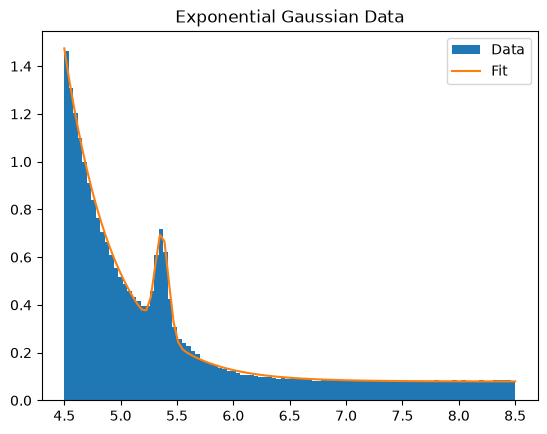

In [322]:
# Plot the data and normalise the histogram to have a total area of 1
plt.hist(data, bins = 100, label = "Data", density = True)
plt.plot(x_array, best_fit_exp_gaus, label = "Fit")
plt.title("Exponential Gaussian Data")
plt.legend()
plt.show()

# Obtain the mass and fraction of the signal

The mass is the mean of the signal peak.

In [323]:
mean_gauss_value = exp_gauss_vals.values["mean_gauss"]
mean_gauss_err = exp_gauss_vals.errors["mean_gauss"]

In [324]:
frac_sig_value = exp_gauss_vals.values["frac_sig"]
frac_sig_err = exp_gauss_vals.errors["frac_sig"]

In [325]:
print(f"Mass: {mean_gauss_value:.3f} ± {mean_gauss_err:.3f}")
print(f"Fraction of the sample that is signal: {frac_sig_value:.3f} ± {frac_sig_err:.3f}")

Mass: 5.366 ± 0.001
Fraction of the sample that is signal: 0.063 ± 0.001


# Correlation between the mass and fraction of the signal

And any other correlations with other parameters in my fit

In [328]:
# Get the covariance matrix
exp_gauss_vals.covariance.correlation()

,frac_sig,frac_exp,slope_exp,mean_gauss,width_gauss
frac_sig,1,-0.3,-0.4,-0.1,0.6
frac_exp,-0.3,1,0.6,0,-0.2
slope_exp,-0.4,0.6,1,0,-0.3
mean_gauss,-0.1,0,0,1,0
width_gauss,0.6,-0.2,-0.3,0,1


The correlation between the mass and fraction of the signal is -0.1 so they are not very correlated.

# Is the fit good quality?

Let's calculate the chi-squared

In [330]:
# Create the histogram
num_bins = 100
counts, bin_edges = np.histogram(data, bins = num_bins)
n_total = len(data)

In [331]:
# Calculate CDF at edges, upper and lower limit of the data
cdf_gauss_edges = norm.cdf(bin_edges, loc = mean_gauss_value, scale = width_gauss_value)
lower_gauss_cdf = norm.cdf(bin_edges[0], loc = mean_gauss_value, scale = width_gauss_value)
upper_gauss_cdf = norm.cdf(bin_edges[-1], loc = mean_gauss_value, scale = width_gauss_value)
prob_gauss = np.diff(cdf_gauss_edges) / (upper_gauss_cdf - lower_gauss_cdf)

In [352]:
# Calculate CDF at edges, upper and lower limit of the data
cdf_exp_edges = scipy.stats.expon.cdf(bin_edges, scale = slope_exp_value)
lower_exp_cdf = scipy.stats.expon.cdf(bin_edges[0], scale = slope_exp_value)
upper_exp_cdf = scipy.stats.expon.cdf(bin_edges[-1], scale = slope_exp_value)

# Normalise the pdf using the cdf 
prob_exp = np.diff(cdf_exp_edges) / (upper_exp_cdf - lower_exp_cdf)

In [353]:
# Constant / uniform difference
prob_flat = np.diff(bin_edges) / (bin_edges[-1] - bin_edges[0])

In [354]:
# Calculate fractions for the background
frac_back = 1 - frac_sig_value
frac_exp_share = frac_back * frac_exp_value
frac_const_share = frac_back - frac_exp_share

In [355]:
# Total expected counts per bin
expected_counts = (frac_exp_share * prob_exp + frac_sig_value * prob_gauss + frac_const_share * prob_flat) * n_total

In [356]:
# Calculate uncertainty
# Poisson counting statistics: sigma = sqrt(counts)
uncertainties = np.sqrt(expected_counts)

In [357]:
# Define a function to calculate chi squared
def calculate_chi_squared(data, model, data_uncertainty):

    data = np.array(data)
    model = np.array(model)
    data_uncertainty = np.array(data_uncertainty)

    chi_squared = np.sum(((data - model) / data_uncertainty) ** 2)

    return chi_squared

In [358]:
# Calculate chi-squared 
chi_squared = calculate_chi_squared(counts, expected_counts, uncertainties)

# Print chi-squared
print(f"Chi-squared: {chi_squared}")

Chi-squared: 625.7936505932981


We expect chi-squared to be ~ (number of data points - number of parameters in the model). This would mean the model describes the data well. 

If chi-squared is much greater than this, the model describe the data poorly. 

If chi-squared is much smaller than this, it suggests the data has uncertainties which are overestimated.

In [ ]:
# Calculate expected chi-squared
# Number of parameters = 5
no_parameters = 5
expected_chi_squared = len(counts) - no_parameters

# Print expected chi-squared
print(f"Expected chi-squared: {expected_chi_squared:.2f}")

Expected chi-squared: 95.00


In [363]:
p = scipy.stats.chi2.sf(chi_squared, 5)
print(p)

5.397357748796642e-133
